In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from google.colab import files

# Upload the original MoMA dataset
uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, low_memory=False)

print("Original dataset shape:", df.shape)
print("Original records:", len(df))
print("Columns:", df.columns.tolist())

df.head()


Saving Artworks.csv to Artworks (1).csv
Original dataset shape: (160700, 30)
Original records: 160700
Columns: ['Title', 'Artist', 'ConstituentID', 'ArtistBio', 'Nationality', 'BeginDate', 'EndDate', 'Gender', 'Date', 'Medium', 'Dimensions', 'CreditLine', 'AccessionNumber', 'Classification', 'Department', 'DateAcquired', 'Cataloged', 'ObjectID', 'URL', 'ImageURL', 'OnView', 'Circumference (cm)', 'Depth (cm)', 'Diameter (cm)', 'Height (cm)', 'Length (cm)', 'Weight (kg)', 'Width (cm)', 'Seat Height (cm)', 'Duration (sec.)']


,Title,Artist,ConstituentID,ArtistBio,Nationality,BeginDate,EndDate,Gender,Date,Medium,...,OnView,Circumference (cm),Depth (cm),Diameter (cm),Height (cm),Length (cm),Weight (kg),Width (cm),Seat Height (cm),Duration (sec.)
0,"Ferdinandsbrücke Project, Vienna, Austria (Ele...",Otto Wagner,6210,"(Austrian, 1841–1918)",(Austrian),(1841),(1918),(male),1896,Ink and cut-and-pasted painted pages on paper,...,NaN,NaN,NaN,NaN,48.6000,NaN,NaN,168.9000,NaN,NaN
1,"City of Music, National Superior Conservatory ...",Christian de Portzamparc,7470,"(French, born 1944)",(French),(1944),(0),(male),1987,Paint and colored pencil on print,...,NaN,NaN,NaN,NaN,40.6401,NaN,NaN,29.8451,NaN,NaN
2,"Villa project, outside Vienna, Austria (Elevat...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, pen, color pencil, ink, and gouache ...",...,NaN,NaN,NaN,NaN,34.3000,NaN,NaN,31.8000,NaN,NaN
3,"The Manhattan Transcripts Project, New York, N...",Bernard Tschumi,7056,"(French and Swiss, born Switzerland 1944)",(),(1944),(0),(male),1980,Photographic reproduction with colored synthet...,...,NaN,NaN,NaN,NaN,50.8000,NaN,NaN,50.8000,NaN,NaN
4,"Villa project, outside Vienna, Austria (Exteri...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, color pencil, ink, and gouache on tr...",...,NaN,NaN,NaN,NaN,38.4000,NaN,NaN,19.1000,NaN,NaN


In [2]:

# ============================================================
# 1. Expand shortened year ranges
# Example: 1960-65 -> 1960-1965
# ============================================================

def expand_short_year(start_year, end_text):
    start_year = int(start_year)
    end_text = str(end_text)

    if len(end_text) == 4:
        return int(end_text)

    digits = len(end_text)
    base = (start_year // (10 ** digits)) * (10 ** digits)
    end_year = base + int(end_text)

    if end_year < start_year:
        end_year += 10 ** digits

    return end_year


# ============================================================
# 2. Parse artwork creation dates
# ============================================================

def parse_moma_date(value, circa_pad=2):

    def result(lower, upper, date_type):
        return lower, upper, (lower + upper) / 2, date_type

    if pd.isna(value):
        return np.nan, np.nan, np.nan, "missing"

    s = str(value).lower().strip()
    s = s.replace("−", "-").replace("–", "-").replace("—", "-")
    s = re.sub(r"\s+", " ", s)

    # Remove outer parentheses
    while s.startswith("(") and s.endswith(")"):
        s = s[1:-1].strip()

    # Unknown dates
    unknown_pattern = (
        r"(?:n\.?\s*d\.?|unknown|unkown|tbd|tbc|"
        r"undated|no date|date unknown|not dated|various|\?)"
    )

    if re.fullmatch(unknown_pattern, s):
        return np.nan, np.nan, np.nan, "unknown"

    # BC / BCE: retained for consistency with previous n=3000
    m = re.search(
        r"(?:(c\.?|ca\.?|circa)\s*)?"
        r"(\d{1,4})\s*"
        r"(?:b\.?\s*c\.?\s*e?\.?|bce)\b",
        s
    )

    if m:
        y = -int(m.group(2))
        if m.group(1):
            return result(y - circa_pad, y + circa_pad, "circa_bc")
        return result(y, y, "bc")

    # Open-ended dates: do not guess a year
    open_patterns = [
        r"^(?:probably\s+)?before\s+\d{4}\??\.?$",
        r"^(?:probably\s+)?after\s+\d{4}\??\.?$",
        r"^\(?\s*(?:probably\s+)?before\s+\d{4}\s*\)?$",
        r"^\(?\s*(?:probably\s+)?after\s+\d{4}\s*\)?$",
        r"^\d{4}\s+(?:or\s+)?before\??\.?$",
        r"^\d{4}\s+(?:or\s+)?after\??\.?$"
    ]

    if any(re.fullmatch(p, s) for p in open_patterns):
        return np.nan, np.nan, np.nan, "open_ended_excluded"

    # Circa year ranges: c. 1938-60
    m = re.match(
        r"^(?:c\.?|ca\.?|circa)\s*(\d{4})\s*-\s*(\d{1,4})",
        s
    )

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))
        return result(lower, upper, "circa_range")

    # Circa single years: c. 1960
    m = re.match(r"^(?:c\.?|ca\.?|circa)\s*(\d{4})\b", s)

    if m:
        y = int(m.group(1))
        return result(y - circa_pad, y + circa_pad, "circa")

    # Alternative years: 1936 or 1937
    m = re.match(r"^(\d{4})\s+or\s+(\d{4})\b", s)

    if m:
        y1, y2 = int(m.group(1)), int(m.group(2))
        return result(min(y1, y2), max(y1, y2), "alternative_years")

    # Year ranges: 1960-1965 or 1960-65
    m = re.match(r"^(\d{4})\s*-\s*(\d{1,4})\b", s)

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))
        return result(lower, upper, "range")

    # Decades: early/mid/late 1960s
    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*(\d{4})s\b",
        s
    )

    if m:
        position = m.group(1) or ""
        base = int(m.group(2))

        if position == "early":
            lower, upper = base, base + 3
        elif position.startswith("mid"):
            lower, upper = base + 4, base + 6
        elif position == "late":
            lower, upper = base + 7, base + 9
        else:
            lower, upper = base, base + 9

        return result(lower, upper, "decade_" + (position or "full"))

    # Centuries: 19th century, late 19th century
    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*"
        r"(\d{1,2})(?:st|nd|rd|th)\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:
        position = m.group(1) or ""
        century = int(m.group(2))
        start = (century - 1) * 100
        end = century * 100 - 1

        if position == "early":
            lower, upper = start, start + 33
        elif position.startswith("mid"):
            lower, upper = start + 34, start + 66
        elif position == "late":
            lower, upper = start + 67, end
        else:
            lower, upper = start, end

        return result(lower, upper, "century_" + (position or "full"))

    # Century ranges: 4th-6th century C.E.
    m = re.match(
        r"^(\d{1,2})(?:st|nd|rd|th)\s*-\s*"
        r"(\d{1,2})(?:st|nd|rd|th)\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:
        c1, c2 = int(m.group(1)), int(m.group(2))
        return result((c1 - 1) * 100, c2 * 100 - 1, "century_range")

    # Exact primary year
    m = re.match(r"^(\d{4})(?!\d)", s)

    if m:
        y = int(m.group(1))
        return result(y, y, "primary_exact_year")

    # Calendar dates: March 12, 1960
    month_pattern = (
        r"^(?:january|february|march|april|may|june|"
        r"july|august|september|october|november|december)"
    )

    if re.match(month_pattern, s):
        m = re.search(r"(?<!\d)(\d{4})(?!\d)", s)
        if m:
            y = int(m.group(1))
            return result(y, y, "calendar_date")

    # Publication-only dates are not creation years
    if re.match(r"^(published|printed|publication|edition)\b", s):
        return np.nan, np.nan, np.nan, "publication_only_excluded"

    # Fallback: first identifiable four-digit year
    m = re.search(r"(?<!\d)(\d{4})(?!\d)", s)

    if m:
        y = int(m.group(1))
        return result(y, y, "fallback_embedded_year")

    return np.nan, np.nan, np.nan, "unparsed"


# ============================================================
# 3. Apply data cleaning
# ============================================================

parsed = df["Date"].apply(parse_moma_date).apply(pd.Series)

parsed.columns = [
    "year_lower",
    "year_upper",
    "year_mid",
    "date_type"
]

df_clean = pd.concat([df, parsed], axis=1)

# Use the same population definition as previous n=3000
years = df_clean["year_mid"].dropna().astype(float)

# ============================================================
# 4. Check cleaned data
# ============================================================

print("Original records:", len(df))
print("Usable records:", len(years))
print("Population mean:", round(years.mean(), 3))
print("Population SD:", round(years.std(ddof=0), 3))

print("\nDate types:")
print(df_clean["date_type"].value_counts())

print("\nExamples of cleaned dates:")
print(
    df_clean[
        ["Date", "year_lower", "year_upper", "year_mid", "date_type"]
    ].head(20)
)

# ============================================================
# 5. Save cleaned dataset
# ============================================================

df_clean.to_csv("Artworks_cleaned_all.csv", index=False)

print("\nCleaned dataset saved successfully.")

# Check consistency with previous experiment
if len(years) != 155119 or not np.isclose(
    years.mean(), 1956.712, atol=0.01
):
    print("WARNING: Results differ from the original n=3000 dataset.")
    print("Check the source CSV and date cleaning rules.")


Original records: 160700
Usable records: 155120
Population mean: 1956.68
Population SD: 36.3

Date types:
date_type
primary_exact_year           107660
range                         32169
circa                          7376
calendar_date                  3430
unknown                        2400
circa_range                    2122
missing                        2016
fallback_embedded_year         1394
decade_full                     645
publication_only_excluded       619
open_ended_excluded             540
decade_early                    275
decade_late                      30
alternative_years                12
unparsed                          5
century_range                     2
century_full                      2
century_late                      1
circa_bc                          1
decade_mid                        1
Name: count, dtype: int64

Examples of cleaned dates:
       Date  year_lower  year_upper  year_mid           date_type
0      1896      1896.0      1896.0    1896.

===== Random Sampling: n=1000 =====
Population mean: 1956.680
Mean of sample means: 1956.657
SD of sample means: 1.069
Mean absolute error: 0.821
Median absolute error: 0.662

===== CLT / SE Comparison =====
Basic theoretical SE: 1.148
SE with FPC: 1.144
Empirical SE: 1.069

First 10 repetitions:


,iteration,sample_size,sample_mean,sample_sd,absolute_error
0,1,1000,1956.2550,32.948803,0.4246
1,2,1000,1954.5295,32.469195,2.1501
2,3,1000,1957.4800,31.297702,0.8004
3,4,1000,1957.7690,33.358251,1.0894
4,5,1000,1954.9780,35.017528,1.7016
5,6,1000,1956.5845,31.843298,0.0951
6,7,1000,1955.5850,31.820690,1.0946
7,8,1000,1955.7010,53.980010,0.9786
8,9,1000,1955.3685,52.694764,1.3111
9,10,1000,1957.0375,33.187562,0.3579


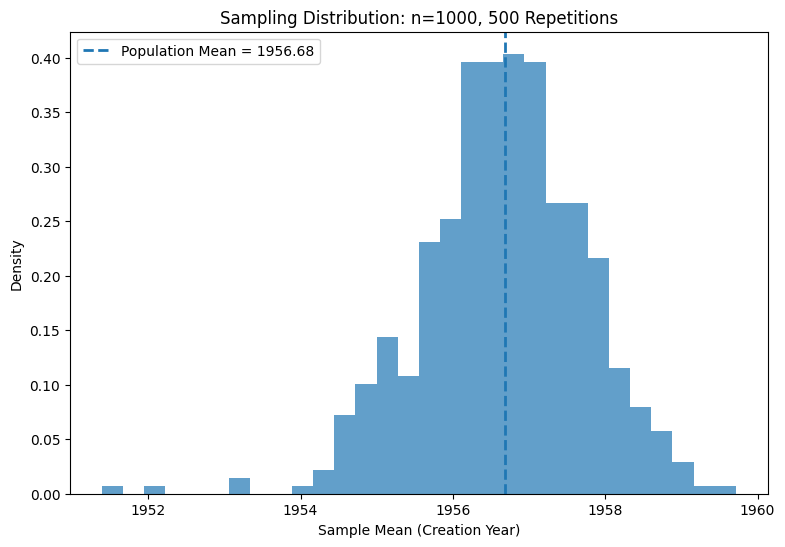

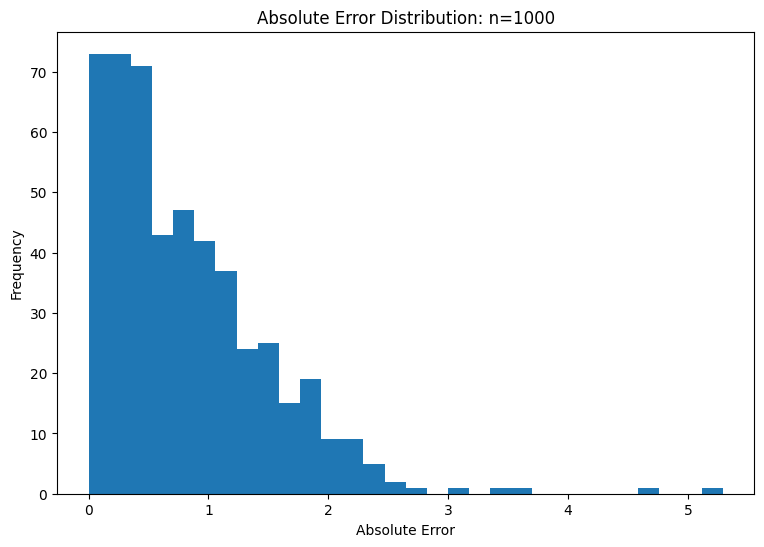

Sampling results saved.


In [3]:

# Random Sampling, n=1000, repeated for 5 times.
# ============================================================
# 1. Population statistics
# ============================================================

N = len(years)
population_mean = years.mean()
population_sd = years.std(ddof=0)

# ============================================================
# 2. Sampling settings
# ============================================================

sample_size = 1000
n_repetitions = 500

rng = np.random.default_rng(42)

# ============================================================
# 3. Repeated random sampling
# ============================================================

results = []

for i in range(n_repetitions):

    sample = rng.choice(
        years.to_numpy(),
        size=sample_size,
        replace=False
    )

    sample_mean = np.mean(sample)
    sample_sd = np.std(sample, ddof=1)
    absolute_error = abs(sample_mean - population_mean)

    results.append({
        "iteration": i + 1,
        "sample_size": sample_size,
        "sample_mean": sample_mean,
        "sample_sd": sample_sd,
        "absolute_error": absolute_error
    })

results_1000_df = pd.DataFrame(results)

# ============================================================
# 4. Calculate summary statistics
# ============================================================

mean_of_sample_means = results_1000_df["sample_mean"].mean()

empirical_se = results_1000_df["sample_mean"].std(ddof=1)

mean_absolute_error = results_1000_df["absolute_error"].mean()

median_absolute_error = results_1000_df["absolute_error"].median()

# Theoretical standard error
theoretical_se = population_sd / np.sqrt(sample_size)

# Finite population correction
fpc = np.sqrt((N - sample_size) / (N - 1))

theoretical_se_fpc = theoretical_se * fpc

# ============================================================
# 5. Display results
# ============================================================

print("===== Random Sampling: n=1000 =====")

print(f"Population mean: {population_mean:.3f}")
print(f"Mean of sample means: {mean_of_sample_means:.3f}")
print(f"SD of sample means: {empirical_se:.3f}")
print(f"Mean absolute error: {mean_absolute_error:.3f}")
print(f"Median absolute error: {median_absolute_error:.3f}")

print("\n===== CLT / SE Comparison =====")

print(f"Basic theoretical SE: {theoretical_se:.3f}")
print(f"SE with FPC: {theoretical_se_fpc:.3f}")
print(f"Empirical SE: {empirical_se:.3f}")

print("\nFirst 10 repetitions:")
display(results_1000_df.head(10))

# ============================================================
# 6. Sampling distribution plot
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    results_1000_df["sample_mean"],
    bins=30,
    density=True,
    alpha=0.7
)

plt.axvline(
    population_mean,
    linestyle="--",
    linewidth=2,
    label=f"Population Mean = {population_mean:.2f}"
)

plt.xlabel("Sample Mean (Creation Year)")
plt.ylabel("Density")
plt.title("Sampling Distribution: n=1000, 500 Repetitions")
plt.legend()
plt.show()

# ============================================================
# 7. Absolute error plot
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(results_1000_df["absolute_error"], bins=30)

plt.xlabel("Absolute Error")
plt.ylabel("Frequency")
plt.title("Absolute Error Distribution: n=1000")
plt.show()

# ============================================================
# 8. Save sampling results
# ============================================================

results_1000_df.to_csv(
    "sampling_results_n1000_500reps.csv",
    index=False
)

print("Sampling results saved.")
